<a href="https://colab.research.google.com/github/PedroJunior56/Projeto-Aplicado-IV/blob/main/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**
# **Documentação do Projeto**

# **Título do Projeto**

## Análise Preditiva de Casos de Dengue em São Paulo para Apoio às Ações de Saúde Pública

In [ ]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Ândria Giovana Oliveira Cabeça da Silva, 10441204' #@param {type:"string"}
Aluno2 = 'Beatriz Ribeiro Porto Liberato, 10441384' #@param {type:"string"}
Aluno3 = 'Dalicio Pereira de Novaes Junior, 10441535' #@param {type:"string"}
Aluno4 = 'Gustavo da Conceição Guimarães, 10723830' #@param {type:"string"}
Aluno5 = 'Pedro Lima da Silva Junior, 10729027' #@param {type:"string"}

# **Resumo**

Solução preditiva para apoiar a antecipação de aumentos de dengue no estado de São Paulo, usando dados semanais do InfoDengue e identificação municipal do IBGE. O pipeline cobre aquisição, qualidade, pré-processamento, EDA, série estadual, divisão temporal, seleção por validação e comparação de Seasonal Naive, SARIMA e Random Forest por MAE, RMSE e MASE. Nesta Etapa 3, o recorte estadual é uma prova de conceito reproduzível.

# **Introdução**

A dengue apresenta forte componente temporal e exige planejamento preventivo. O objetivo é desenvolver um produto analítico preditivo para antecipar períodos de aumento no estado de São Paulo. O projeto busca obter e estruturar os dados, avaliar qualidade, caracterizar tendência e sazonalidade, implementar modelos, selecionar hiperparâmetros com validação temporal e comparar desempenho. A proposta se relaciona ao ODS 3 — Saúde e Bem-Estar.

# **Referencial Teórico**

Séries temporais podem apresentar tendência, sazonalidade e autocorrelação (HYNDMAN; ATHANASOPOULOS, 2021). ARIMA/SARIMA modelam componentes autorregressivos, diferenciação, médias móveis e sazonalidade (BOX; JENKINS, 1976). Random Forest combina múltiplas árvores para reduzir variância (BREIMAN, 2001). Neste projeto, a periodicidade semanal justifica baseline sazonal e SARIMA anual; o Random Forest usa apenas defasagens, médias móveis passadas e calendário. Hiperparâmetros são escolhidos na validação, preservando o teste para a avaliação final.

# **Diagrama de Solução**

**InfoDengue + IBGE → SP (2020–atual) → qualidade/pré-processamento → EDA e série semanal → treino/validação/teste → seleção de hiperparâmetros → Seasonal Naive / SARIMA / Random Forest → MAE, RMSE e MASE → interpretação.**

# **EDA e Pré-processamento dos dados**

O recorte considera municípios paulistas e registros de 01/01/2020 até a data de execução. O CSV pode vir do `base.extração.ipynb`; se ausente, a célula também consulta IBGE/InfoDengue. O tratamento converte datas, remove duplicidades município×semana, restringe o período e agrega a série estadual. A EDA mostra nulos, estatísticas, evolução, distribuição, sazonalidade e correlações. Indicadores derivados dos próprios casos são apenas descritivos e não entram contemporaneamente na previsão.

Dimensão: (228330, 32) Período: 2020-01-05 a 2026-10-11


,nulos,%
casprov_est,228330,100.00
casprov_est_min,228330,100.00
casprov_est_max,228330,100.00
casconf,228330,100.00
umidmed,4682,2.05
umidmin,4682,2.05
tempmed,4682,2.05
tempmax,4682,2.05
umidmax,1811,0.79
casos_est_max,50,0.02


,count,mean,std,min,25%,50%,75%,max
casos_est,228330.0,37.498739,616.373766,0.000000,0.000000,1.000000,10.000000,85389.000000
Rt,228330.0,1.309882,2.973277,0.000000,0.000000,0.604990,1.284983,18.521618
p_rt1,228330.0,0.344497,0.374376,0.000000,0.000000,0.182970,0.695589,1.000000
p_inc100k,228330.0,67.661809,190.424432,0.000000,0.000000,7.178309,43.939950,6149.560500
tempmed,223648.0,22.650719,3.410883,11.014243,20.365626,22.909239,25.115389,35.166667
umidmed,223648.0,67.868797,13.313957,17.318492,59.455442,69.669493,77.896359,99.622475


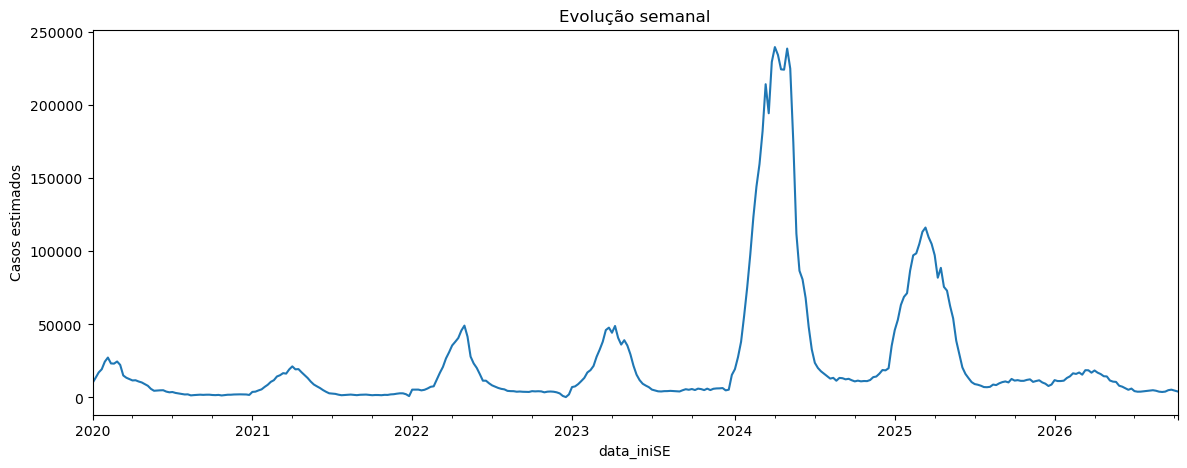

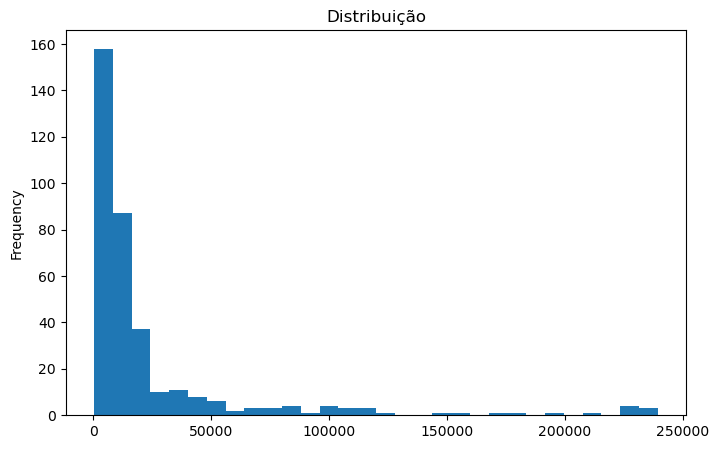

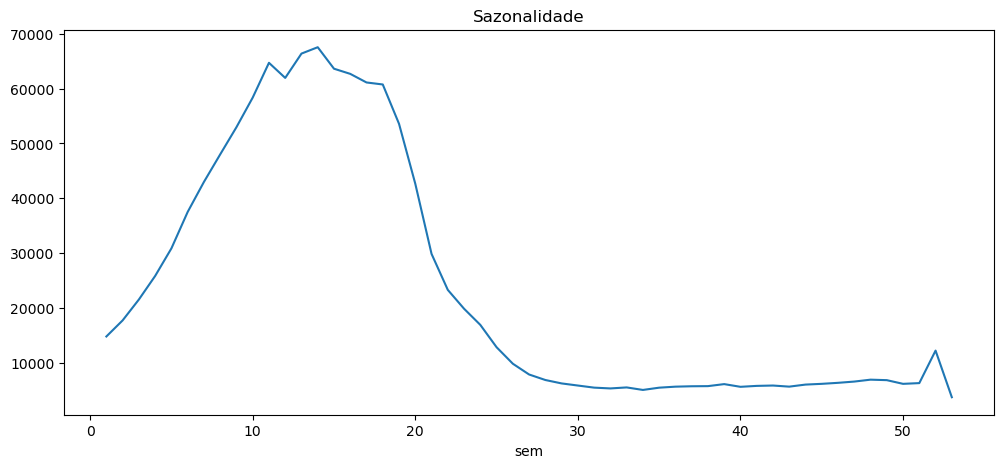

,casos_est,Rt,p_rt1,p_inc100k,tempmed,umidmed
casos_est,1.000,-0.002,0.041,0.114,-0.005,0.027
Rt,-0.002,1.000,0.551,0.037,0.082,0.028
p_rt1,0.041,0.551,1.000,0.264,0.155,0.105
p_inc100k,0.114,0.037,0.264,1.000,0.122,0.052
tempmed,-0.005,0.082,0.155,0.122,1.000,-0.351
umidmed,0.027,0.028,0.105,0.052,-0.351,1.000


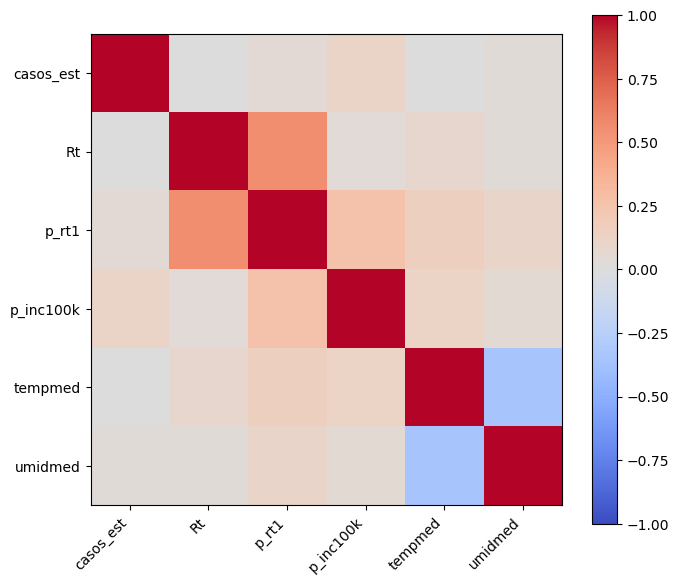

In [3]:

import io,requests,numpy as np,pandas as pd,matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor,as_completed
from tqdm.auto import tqdm
from IPython.display import display
ANO=2020; HOJE=pd.Timestamp.today().normalize(); CSV=Path("Base_Dengue_SP_2020_ate_hoje.csv")
def conv(s):
 x=s.astype("string").str[:10]; d=pd.to_datetime(x,format="%Y-%m-%d",errors="coerce"); m=d.isna()
 d.loc[m]=pd.to_datetime(x.loc[m],format="%d/%m/%Y",errors="coerce"); return d
def extrair():
 ms=requests.get("https://servicodados.ibge.gov.br/api/v1/localidades/municipios",timeout=60).json()
 def uf(m):
  try:return m["regiao-imediata"]["regiao-intermediaria"]["UF"]["sigla"]
  except:return m["microrregiao"]["mesorregiao"]["UF"]["sigla"]
 ms=[(m["id"],m["nome"]) for m in ms if uf(m)=="SP"]
 def q(x):
  cod,nome=x; out=[]
  for y in range(ANO,HOJE.year+1):
   try:
    r=requests.get("https://info.dengue.mat.br/api/alertcity",params={"geocode":cod,"disease":"dengue","format":"csv","ew_start":1,"ew_end":53,"ey_start":y,"ey_end":y},timeout=90)
    if r.ok and r.text.strip() and not r.text.startswith("[EE]"):
     z=pd.read_csv(io.StringIO(r.text)); z["geocode"]=cod; z["municipio_nome"]=nome; z["UF"]="SP"; out.append(z)
   except: pass
  return pd.concat(out,ignore_index=True) if out else None
 out=[]
 with ThreadPoolExecutor(max_workers=8) as ex:
  fs=[ex.submit(q,m) for m in ms]
  for f in tqdm(as_completed(fs),total=len(fs),desc="InfoDengue SP"):
   z=f.result()
   if z is not None: out.append(z)
 if not out: raise RuntimeError("Sem dados do InfoDengue.")
 return pd.concat(out,ignore_index=True)
df0=pd.read_csv(CSV,low_memory=False) if CSV.exists() else extrair()
if "data_ini_SE" in df0 and "data_iniSE" not in df0: df0=df0.rename(columns={"data_ini_SE":"data_iniSE"})
df0["data_iniSE"]=conv(df0["data_iniSE"]); df=df0[df0.data_iniSE.notna()].copy()
df=df[(df.data_iniSE>=pd.Timestamp("2020-01-01"))&(df.data_iniSE<=HOJE)]
if "UF" in df: df=df[df.UF.astype(str).str.upper().eq("SP")]
df=df.drop_duplicates(["geocode","data_iniSE"] if "geocode" in df else None,keep="last").sort_values("data_iniSE")
if not CSV.exists(): df.to_csv(CSV,index=False,encoding="utf-8-sig",date_format="%Y-%m-%d")
TARGET="casos_est" if "casos_est" in df else "casos"
cols=[c for c in [TARGET,"Rt","p_rt1","p_inc100k","tempmed","umidmed"] if c in df]
for c in cols: df[c]=pd.to_numeric(df[c],errors="coerce")
print("Dimensão:",df.shape,"Período:",df.data_iniSE.min().date(),"a",df.data_iniSE.max().date())
display(pd.DataFrame({"nulos":df.isna().sum(),"%":(100*df.isna().mean()).round(2)}).sort_values("%",ascending=False)); display(df[cols].describe().T)
agg={TARGET:"sum",**{c:"mean" for c in cols if c!=TARGET}}
serie=df.groupby("data_iniSE").agg(agg).sort_index(); serie=serie.reindex(pd.date_range(serie.index.min(),serie.index.max(),freq="W-SUN")); serie.index.name="data_iniSE"
serie_modelo=serie.copy(); serie_modelo[TARGET]=serie_modelo[TARGET].interpolate(limit_direction="both")
serie[TARGET].plot(figsize=(14,5),title="Evolução semanal",ylabel="Casos estimados"); plt.show()
serie[TARGET].plot.hist(bins=30,title="Distribuição",figsize=(8,5)); plt.show()
serie.assign(sem=serie.index.isocalendar().week.astype(int)).groupby("sem")[TARGET].mean().plot(figsize=(12,5),title="Sazonalidade"); plt.show()
if len(cols)>1:
 c=df[cols].corr(); display(c.round(3)); fig,ax=plt.subplots(figsize=(7,6)); im=ax.imshow(c,vmin=-1,vmax=1,cmap="coolwarm")
 ax.set_xticks(range(len(cols)),cols,rotation=45,ha="right"); ax.set_yticks(range(len(cols)),cols); fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

# **Modelos**

Comparam-se: **Seasonal Naive (52 semanas)**; **SARIMA**, com ordens escolhidas na validação; e **Random Forest**, com lags/médias móveis passadas e calendário, também ajustado pela validação. A divisão é cronológica (~70% treino, 15% validação, 15% teste). Após a escolha dos hiperparâmetros, cada modelo é reestimado com treino+validação e avaliado uma única vez no teste. As métricas são MAE, RMSE e MASE; MASE<1 indica desempenho superior à referência sazonal da escala.

Treino/validação/teste: 247 53 54


,order,seasonal_order,MAE_valid,RMSE_valid
1,"(0, 1, 1)","(1, 1, 0, 52)",31985.843,49544.644
0,"(1, 1, 0)","(1, 1, 0, 52)",42752.269,66922.016
3,"(1, 1, 1)","(0, 1, 1, 52)",43399.737,68114.758
2,"(1, 1, 1)","(1, 1, 0, 52)",53278.992,84505.866


,n_estimators,max_depth,min_samples_leaf,MAE_valid,RMSE_valid
1,300,8.0,2,29061.889,44596.993
0,200,8.0,1,29067.033,44589.403
3,400,NaN,2,29107.988,44607.932
2,300,12.0,1,29124.172,44624.590


,Modelo,MAE,RMSE,MASE,N_teste
0,Random Forest recursivo,4189.561,4684.946,0.174,54
1,Seasonal Naive,29640.333,43870.787,1.233,54
2,SARIMA,62117.630,93301.159,2.584,54


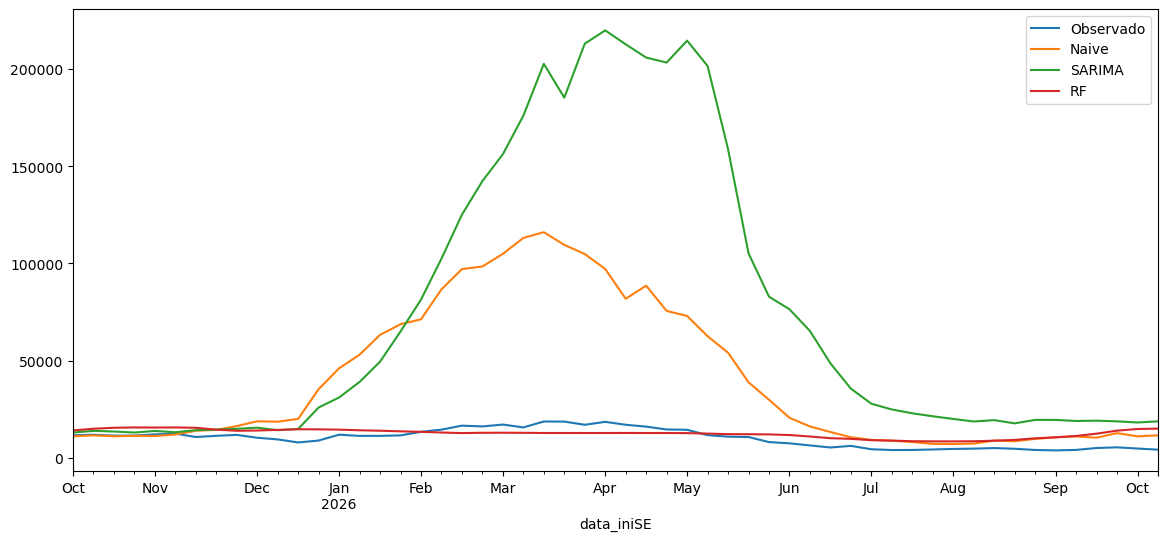

,importancia
lag1,0.9402
lag2,0.0232
lag26,0.0133
m4,0.0089
cos,0.0031
lag52,0.0030
lag13,0.0023
lag8,0.0022
m13,0.0016
lag4,0.0015


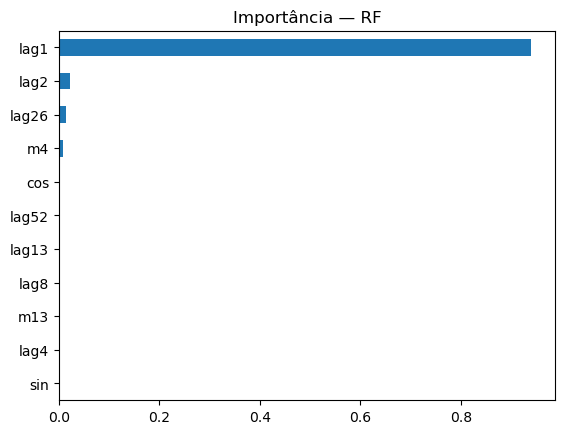

### Síntese automática
**Random Forest recursivo** teve menor RMSE: MAE=4189.561, RMSE=4684.946, MASE=0.174; redução de 89.3% no RMSE vs. Seasonal Naive. Hiperparâmetros foram escolhidos só na validação; o teste foi usado apenas no final.

In [4]:

import warnings,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")
d=serie_modelo[[TARGET]].dropna(); n=len(d); a,b=int(n*.70),int(n*.85); tr,va,te=d.iloc[:a],d.iloc[a:b],d.iloc[b:]; tv=d.iloc[:b]
print("Treino/validação/teste:",len(tr),len(va),len(te))
def rmse(y,p):return np.sqrt(mean_squared_error(y,p))
def mase(y,p):
 x=tv[TARGET].to_numpy(); e=np.mean(np.abs(x[52:]-x[:-52])); return np.mean(np.abs(np.asarray(y)-np.asarray(p)))/e
def av(nome,y,p):return {"Modelo":nome,"MAE":mean_absolute_error(y,p),"RMSE":rmse(y,p),"MASE":mase(y,p),"N_teste":len(y)}
def naive(h,idx):
 h=list(map(float,h));o=[]
 for _ in idx:v=max(0.,h[-52]);o.append(v);h.append(v)
 return pd.Series(o,index=idx)
pn=naive(tv[TARGET],te.index); rn=av("Seasonal Naive",te[TARGET],pn)
gs=[((1,1,0),(1,1,0,52)),((0,1,1),(1,1,0,52)),((1,1,1),(1,1,0,52)),((1,1,1),(0,1,1,52))]
v=[]
for o,s in gs:
 try:
  f=SARIMAX(tr[TARGET],order=o,seasonal_order=s,enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=100)
  p=pd.Series(f.forecast(len(va)),index=va.index).clip(lower=0); v.append([o,s,mean_absolute_error(va[TARGET],p),rmse(va[TARGET],p)])
 except:v.append([o,s,np.inf,np.inf])
sv=pd.DataFrame(v,columns=["order","seasonal_order","MAE_valid","RMSE_valid"]).sort_values("MAE_valid"); display(sv.round(3))
o,s=sv.iloc[0][["order","seasonal_order"]]
f=SARIMAX(tv[TARGET],order=tuple(o),seasonal_order=tuple(s),enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=120)
ps=pd.Series(f.forecast(len(te)),index=te.index).clip(lower=0); rs=av("SARIMA",te[TARGET],ps)
L=[1,2,4,8,13,26,52]
def fx(x):
 z=pd.DataFrame(index=x.index)
 for k in L:z[f"lag{k}"]=x[TARGET].shift(k)
 z["m4"]=x[TARGET].shift(1).rolling(4).mean();z["m13"]=x[TARGET].shift(1).rolling(13).mean();w=z.index.isocalendar().week.astype(int);z["sin"]=np.sin(2*np.pi*w/52);z["cos"]=np.cos(2*np.pi*w/52);z[TARGET]=x[TARGET];return z.dropna()
def row(h,t):
 w=int(t.isocalendar().week);return {**{f"lag{k}":h[-k] for k in L},"m4":np.mean(h[-4:]),"m13":np.mean(h[-13:]),"sin":np.sin(2*np.pi*w/52),"cos":np.cos(2*np.pi*w/52)}
def pred(m,h,idx,F):
 h=list(map(float,h));o=[]
 for t in idx:v=max(0.,float(m.predict(pd.DataFrame([row(h,t)],columns=F))[0]));o.append(v);h.append(v)
 return pd.Series(o,index=idx)
bt=fx(tr);F=[c for c in bt if c!=TARGET];vr=[]
for ne,md,ml in [(200,8,1),(300,8,2),(300,12,1),(400,None,2)]:
 m=RandomForestRegressor(n_estimators=ne,max_depth=md,min_samples_leaf=ml,random_state=42,n_jobs=-1).fit(bt[F],bt[TARGET]);p=pred(m,tr[TARGET],va.index,F);vr.append([ne,md,ml,mean_absolute_error(va[TARGET],p),rmse(va[TARGET],p)])
rv=pd.DataFrame(vr,columns=["n_estimators","max_depth","min_samples_leaf","MAE_valid","RMSE_valid"]).sort_values("MAE_valid");display(rv.round(3))
r=rv.iloc[0];bt=fx(tv);F=[c for c in bt if c!=TARGET];rf=RandomForestRegressor(n_estimators=int(r.n_estimators),max_depth=None if pd.isna(r.max_depth) else int(r.max_depth),min_samples_leaf=int(r.min_samples_leaf),random_state=42,n_jobs=-1).fit(bt[F],bt[TARGET])
pr=pred(rf,tv[TARGET],te.index,F);rr=av("Random Forest recursivo",te[TARGET],pr)
res=pd.DataFrame([rn,rs,rr]).sort_values("RMSE").reset_index(drop=True);res[["MAE","RMSE","MASE"]]=res[["MAE","RMSE","MASE"]].round(3);display(res)
ax=te[TARGET].plot(figsize=(14,6),label="Observado");pn.plot(ax=ax,label="Naive");ps.plot(ax=ax,label="SARIMA");pr.plot(ax=ax,label="RF");ax.legend();plt.show()
imp=pd.Series(rf.feature_importances_,index=F).sort_values(ascending=False);display(imp.to_frame("importancia").round(4));imp.sort_values().plot.barh(title="Importância — RF");plt.show()
best=res.iloc[0];base=float(res.loc[res.Modelo.eq("Seasonal Naive"),"RMSE"].iloc[0]);ganho=100*(base-best.RMSE)/base
display(Markdown(f"### Síntese automática\n**{best.Modelo}** teve menor RMSE: MAE={best.MAE:.3f}, RMSE={best.RMSE:.3f}, MASE={best.MASE:.3f}; redução de {ganho:.1f}% no RMSE vs. Seasonal Naive. Hiperparâmetros foram escolhidos só na validação; o teste foi usado apenas no final."))

# **Resultados**

A execução mostra: tabelas de validação do SARIMA e do Random Forest, métricas finais no teste, gráfico observado×previsto, importância das variáveis e uma síntese automática do melhor modelo. Assim, os valores permanecem ligados à execução corrente e não ficam desatualizados.

## Cronograma atualizado

| Período | Atividade | Situação |
|---|---|---|
| 29/09–05/10 | Preparação dos dados | Concluído |
| 06/10–11/10 | Definição das técnicas | Concluído |
| 12/10–18/10 | Implementação | Concluído |
| 19/10–22/10 | Avaliação/validação | Concluído |
| 23/10–26/10 | Comparação e documentação | Concluído |
| 27/10–15/11 | Revisão, análise crítica e refinamento | Planejado |
| 16/11–24/11 | Melhorias e produto analítico | Planejado |
| 25/11–30/11 | Documentação, apresentação e entrega final | Planejado |

# **Dicussão e Conclusão**

A Etapa 3 consolida um pipeline reproduzível e uma comparação metodologicamente mais consistente: hiperparâmetros são escolhidos na validação e o teste fica reservado para a avaliação final. O modelo com menor erro deve ser entendido como o melhor **no horizonte avaliado**, não como solução definitiva para todos os ciclos epidêmicos. No Random Forest, forte importância de lags recentes pode explicar bom desempenho em períodos estáveis sem garantir antecipação de surtos abruptos.

As principais limitações são agregação estadual, heterogeneidade municipal, revisões do InfoDengue, ausências climáticas e picos muito distintos entre anos. Na Etapa 4, recomenda-se validação em múltiplas janelas, regressoras climáticas defasadas e avaliação municipal/regional. A síntese automática da célula de modelagem registra os resultados quantitativos da execução corrente.

# **Apresentação**

**Link do vídeo:** _a inserir na entrega final_

# **Referências**

BOX, G. E. P.; JENKINS, G. M. *Time Series Analysis: Forecasting and Control*. Holden-Day, 1976.

BREIMAN, L. Random Forests. *Machine Learning*, v. 45, p. 5–32, 2001.

HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. OTexts, 2021.

INFODENGUE. **API: acesso aos dados epidemiológicos**. <https://info.dengue.mat.br>. Acesso em: 20 ago. 2026.

IBGE. **API de localidades**. <https://servicodados.ibge.gov.br/api/docs/localidades>. Acesso em: 26 out. 2026.

RUMELHART, D. E. et al. Learning representations by back-propagating errors. *Nature*, v. 323, p. 533–536, 1986.

ZHANG, G. P. Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, v. 50, p. 159–175, 2003.